# **Diabetes Progression Prediction Using Artificial Neural Networks**



# Loading and Preprocessing

In [2]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

In [3]:
diabetis=load_diabetes()
X=pd.DataFrame(
    diabetis.data,
    columns=diabetis.feature_names
)
y=pd.DataFrame(
    diabetis.target,columns=["progression"]
)


In [4]:
df=X.copy()
df["progression"]=y
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,progression
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [5]:
print("\nStatistical summary:")
display(df.describe())


Statistical summary:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,progression
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


In [6]:
print("Dataset shape:", df.shape)

print("\nDataset information:")
df.info()



Dataset shape: (442, 11)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          442 non-null    float64
 1   sex          442 non-null    float64
 2   bmi          442 non-null    float64
 3   bp           442 non-null    float64
 4   s1           442 non-null    float64
 5   s2           442 non-null    float64
 6   s3           442 non-null    float64
 7   s4           442 non-null    float64
 8   s5           442 non-null    float64
 9   s6           442 non-null    float64
 10  progression  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


In [7]:
#Handle any missing values if present.
df.isnull().sum()

,0
age,0
sex,0
bmi,0
bp,0
s1,0
s2,0
s3,0
s4,0
s5,0
s6,0


In [8]:
#Normalize the features to ensure better performance of the ANN model.
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)


In [9]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)


X_train shape: (353, 10)
X_test shape: (89, 10)


# Exploratory Data Analysis (EDA)

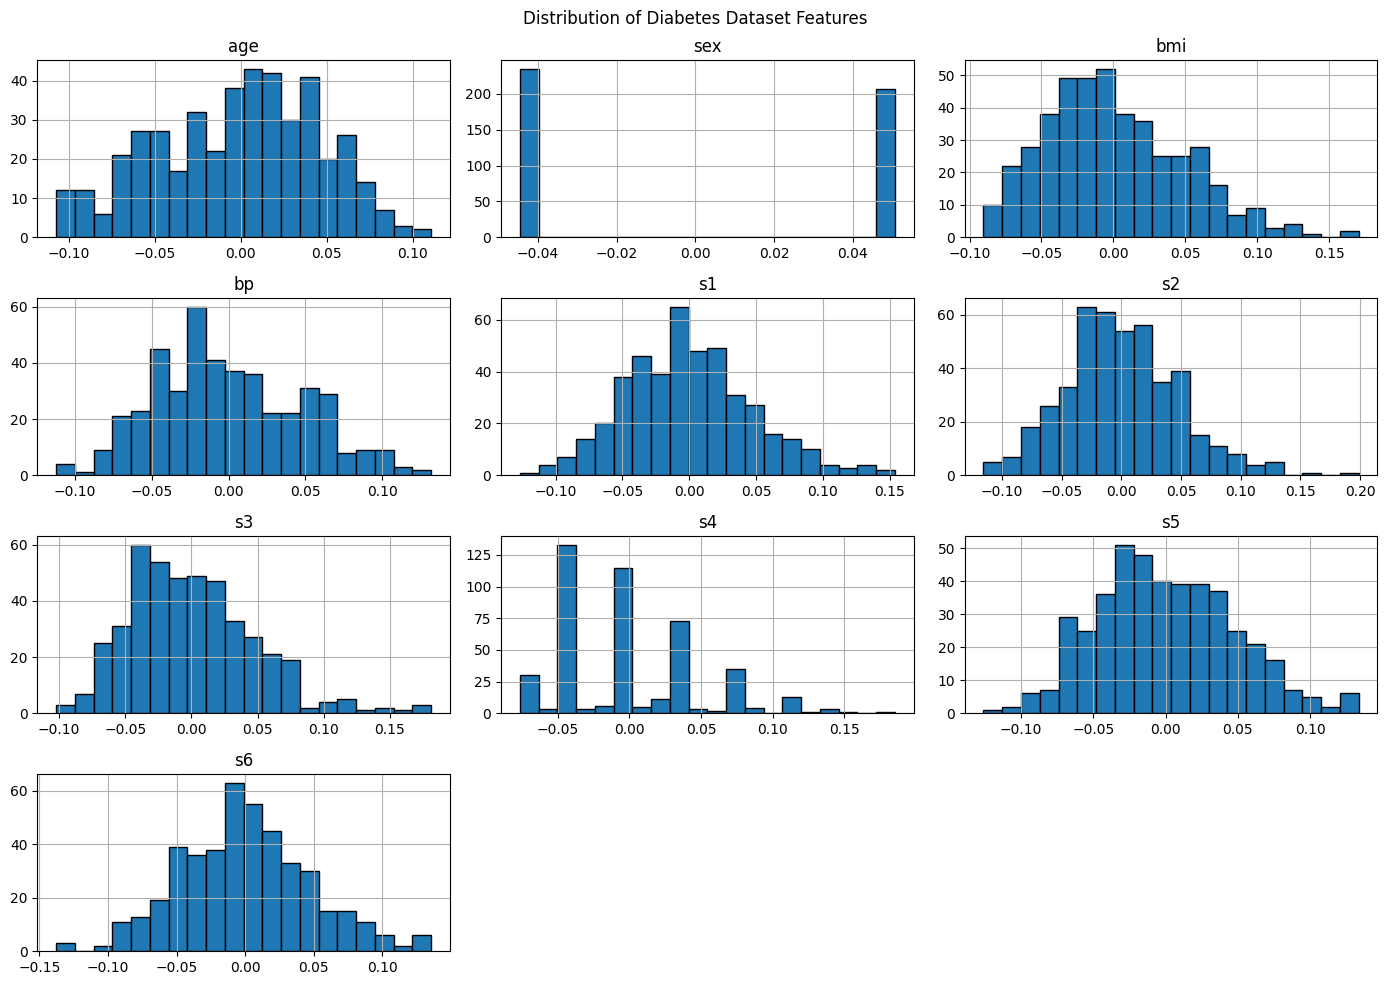

In [10]:
#Distribution of the features
import matplotlib.pyplot as plt
import seaborn as sns
X.hist(
    figsize=(14, 10),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Diabetes Dataset Features")
plt.tight_layout()
plt.show()

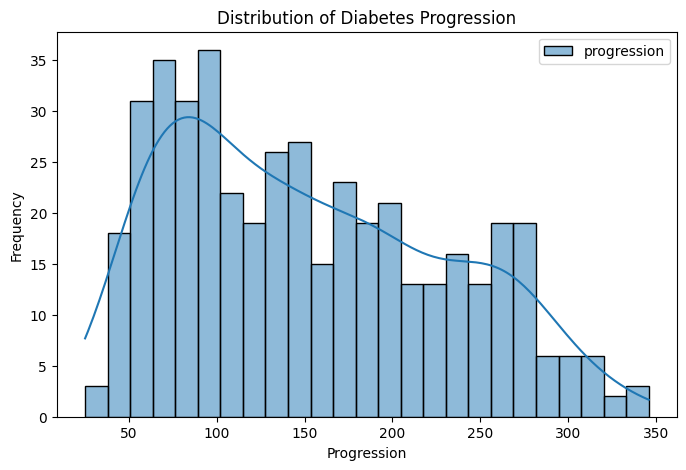

In [11]:
#Distribution of the target variable
plt.figure(figsize=(8, 5))

sns.histplot(y, kde=True, bins=25)

plt.title("Distribution of Diabetes Progression")
plt.xlabel("Progression")
plt.ylabel("Frequency")

plt.show()

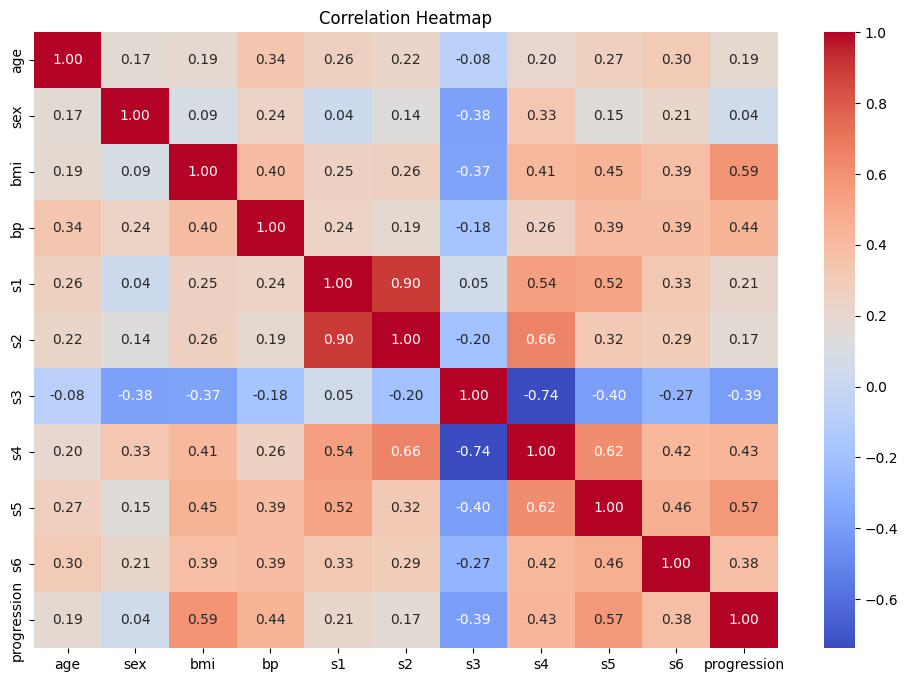

In [12]:
#Correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

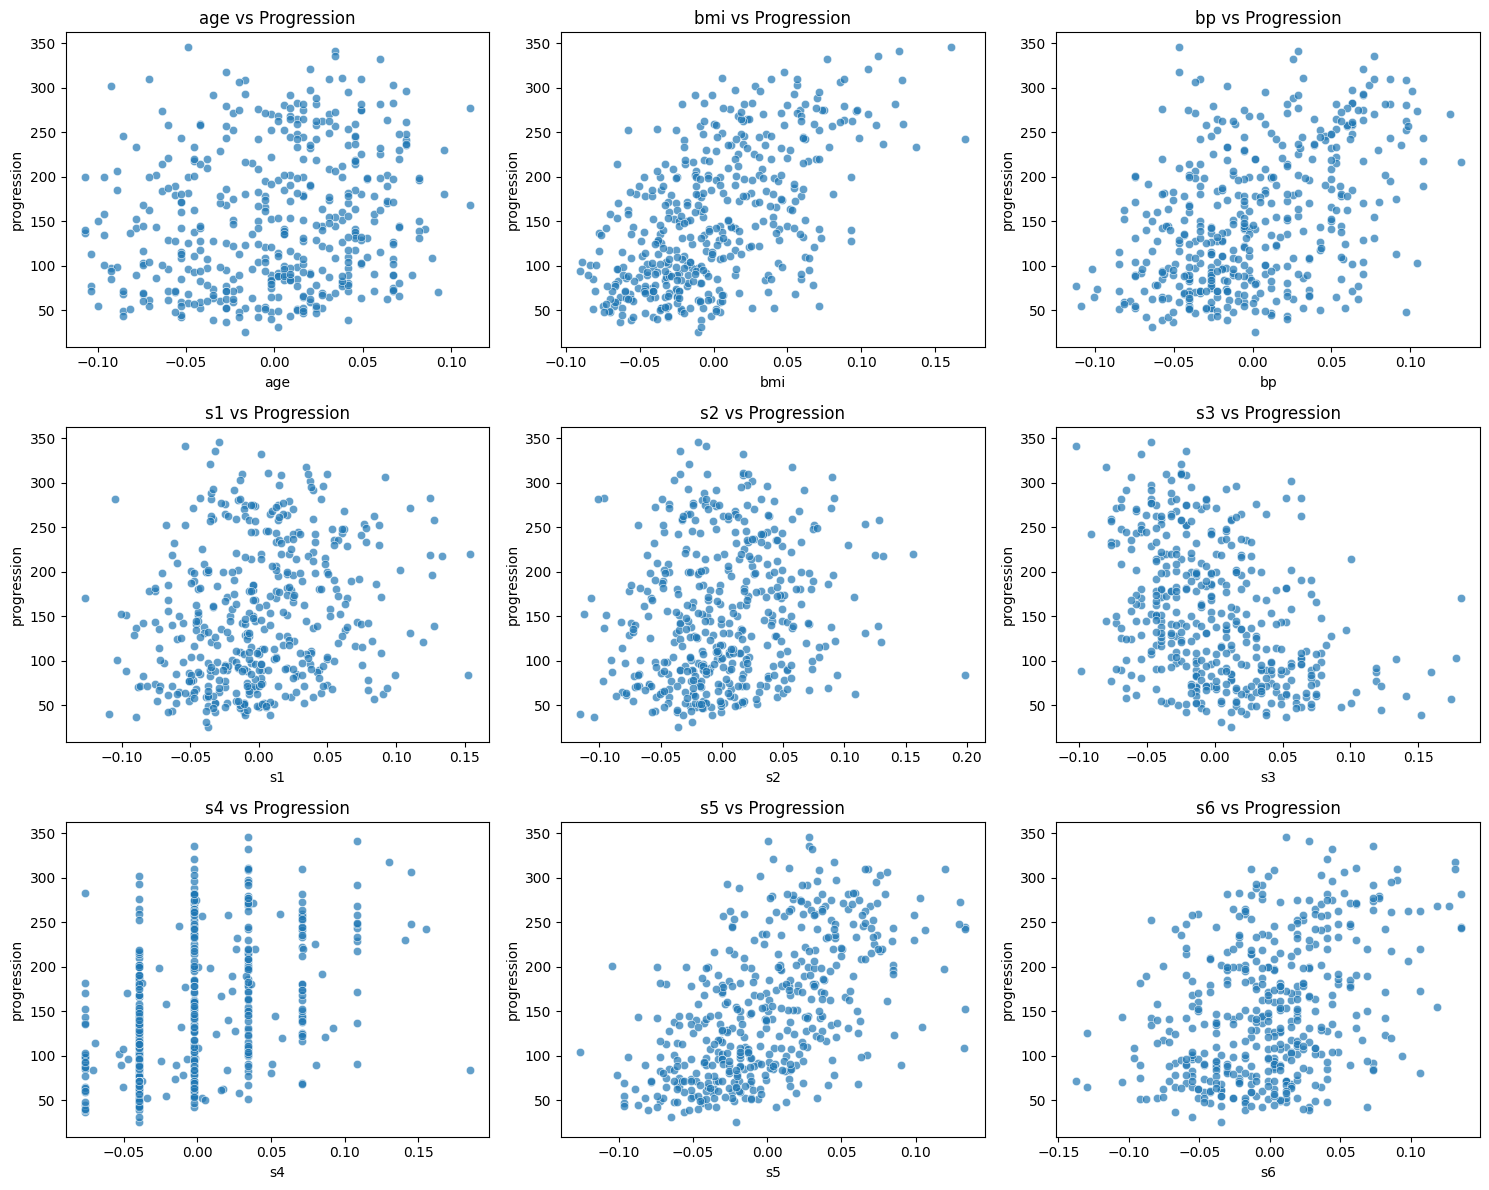

In [13]:
#Relationship between features and target
features = ["age", "bmi", "bp", "s1", "s2", "s3", "s4", "s5", "s6"]

fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for feature, ax in zip(features, axes.flatten()):
    sns.scatterplot(
        data=df,
        x=feature,
        y="progression",
        ax=ax,
        alpha=0.7
    )
    ax.set_title(f"{feature} vs Progression")

plt.tight_layout()
plt.show()

# Building the ANN Model

In [14]:
#Design a simple ANN architecture with at least one hidden layer.
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

baseline_model = Sequential([
    tf.keras.Input(shape=(10,)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(1, activation="linear")
])

baseline_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,817 (11.00 KB)

 Trainable params: 2,817 (11.00 KB)

 Non-trainable params: 0 (0.00 B)

# Training the ANN Model

In [15]:

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

history_baseline = baseline_model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=200,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 4s 226ms/step - loss: 31454.8223 - mae: 158.4171 - val_loss: 22343.0352 - val_mae: 133.5571
Epoch 2/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 31270.0488 - mae: 157.8494 - val_loss: 22196.3809 - val_mae: 133.0266
Epoch 3/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 31071.5000 - mae: 157.2434 - val_loss: 22037.9160 - val_mae: 132.4497
Epoch 4/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 30853.9121 - mae: 156.5729 - val_loss: 21849.6699 - val_mae: 131.7675
Epoch 5/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 30588.4902 - mae: 155.7440 - val_loss: 21620.8457 - val_mae: 130.9451
Epoch 6/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 30248.2129 - mae: 154.7281 - val_loss: 21341.5254 - val_mae: 129.9402
Epoch 7/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 29820.9961 - mae: 153.4450 - val_loss: 21000.3594 - val_mae: 128.7191
Epoch 8/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 29290.9590 - mae: 151.8941 - val_loss: 20587.

# Evaluating the Model

In [24]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
y_pred_baseline = baseline_model.predict(
    X_test_scaled
).flatten()

mse_baseline = mean_squared_error(y_test, y_pred_baseline)
rmse_baseline = np.sqrt(mse_baseline)
mae_baseline = mean_absolute_error(y_test, y_pred_baseline)
r2_baseline = r2_score(y_test, y_pred_baseline)

print("Baseline Model Performance")
print("--------------------------")
print(f"MSE  : {mse_baseline:.2f}")
print(f"RMSE : {rmse_baseline:.2f}")
print(f"MAE  : {mae_baseline:.2f}")
print(f"R2   : {r2_baseline:.4f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
Baseline Model Performance
--------------------------
MSE  : 2954.88
RMSE : 54.36
MAE  : 43.26
R2   : 0.4423


# Improving the Model

In [32]:
def build_model(hidden_layers, learning_rate=0.001, dropout=0.0):
    model = Sequential()
    model.add(tf.keras.Input(shape=(10,)))

    for units in hidden_layers:
        model.add(Dense(units, activation="relu"))

        if dropout > 0:
            model.add(Dropout(dropout))

    model.add(Dense(1, activation="linear"))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="mse",
        metrics=["mae"]
    )


    return model


In [33]:
experiments = [
    {
        "name": "Baseline (64, 32)",
        "layers": [64, 32],
        "lr": 0.001,
        "dropout": 0.0
    },
    {
        "name": "Wider (128, 64)",
        "layers": [128, 64],
        "lr": 0.001,
        "dropout": 0.0
    },
    {
        "name": "Regularized (64, 32)",
        "layers": [64, 32],
        "lr": 0.001,
        "dropout": 0.2
    },
    {
        "name": "Smaller (32, 16)",
        "layers": [32, 16],
        "lr": 0.0005,
        "dropout": 0.0
    }
]

results = []
trained_models = {}

for exp in experiments:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = build_model(
        hidden_layers=exp["layers"],
        learning_rate=exp["lr"],
        dropout=exp["dropout"]
    )

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=20,
        restore_best_weights=True
    )

    history = model.fit(
        X_train_scaled,
        y_train,
        validation_split=0.20,
        epochs=200,
        batch_size=32,
        callbacks=[early_stop],
        verbose=0
    )

    predictions = model.predict(
        X_test_scaled,
        verbose=0
    ).flatten()

    results.append({
        "Model": exp["name"],
        "MSE": mean_squared_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "MAE": mean_absolute_error(y_test, predictions),
        "R2 Score": r2_score(y_test, predictions),
        "Epochs": len(history.history["loss"])
    })

    trained_models[exp["name"]] = model

    print("Completed:", exp["name"])

Completed: Baseline (64, 32)
Completed: Wider (128, 64)
Completed: Regularized (64, 32)
Completed: Smaller (32, 16)


In [19]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

display(results_df.round(4))

,Model,MSE,RMSE,MAE,R2 Score,Epochs
0,"Regularized (64, 32)",2881.5054,53.6797,42.9979,0.4561,136
1,"Baseline (64, 32)",2930.4910,54.1340,43.4067,0.4469,125
2,"Wider (128, 64)",3011.0178,54.8727,43.6513,0.4317,83
3,"Smaller (32, 16)",3639.4160,60.3276,47.8202,0.3131,200


In [34]:
#Identify the best model
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best model based on test RMSE:", best_model_name)
print(results_df.iloc[0])

Best model based on test RMSE: Regularized (64, 32)
Model       Regularized (64, 32)
MSE                  2881.505371
RMSE                   53.679655
MAE                    42.997932
R2 Score                 0.45613
Epochs                       136
Name: 0, dtype: object


**Model Improvement and Performance Comparison**

The **regularized model** achieved the best performance, with an MSE of 2881.5054, RMSE of 53.6797, MAE of 42.9979, and R² score of 0.4561.

Compared with the baseline model from the same experiment table, the regularized model reduced RMSE from 54.1340 to 53.6797, an improvement of approximately **0.84%.** The R² score increased from 0.4469 to 0.4561, indicating a modest increase in the proportion of variance explained by the model.